**PLA**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Dataset & Drop Non-Predictive Features
path=('/content/drive/My Drive/ML Lab/Exp09/sales_data_sample.csv')
df = pd.read_csv(path, encoding='latin1')
# Remove raw identifier strings, contact names, and exact addresses
columns_to_drop = [
    'ORDERNUMBER', 'ORDERDATE', 'CUSTOMERNAME', 'PHONE',
    'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE',
    'POSTALCODE', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'PRODUCTCODE'
]
df_cleaned = df.drop(columns=columns_to_drop)
# Target: Revenue Deal Size
target_col = 'DEALSIZE'
y = df_cleaned[target_col]
X_raw = df_cleaned.drop(columns=[target_col])

# One-hot encode remaining categorical variables
X = pd.get_dummies(X_raw, drop_first=True)
print(f"Dataset shape after feature pruning and encoding: {X.shape[0]} rows, {X.shape[1]} features")
print(f"Class distribution:\n{y.value_counts()}\n")

Dataset shape after feature pruning and encoding: 2823 rows, 39 features
Class distribution:
DEALSIZE
Medium    1384
Small     1282
Large      157
Name: count, dtype: int64



Cumulative Explained Variance (Top 10 Components):
  PC1: 6.91%
  PC2: 13.26%
  PC3: 19.17%
  PC4: 24.35%
  PC5: 28.76%
  PC6: 32.24%
  PC7: 35.61%
  PC8: 38.95%
  PC9: 42.14%
  PC10: 45.28%

Retained 28 components to capture >= 90% variance.



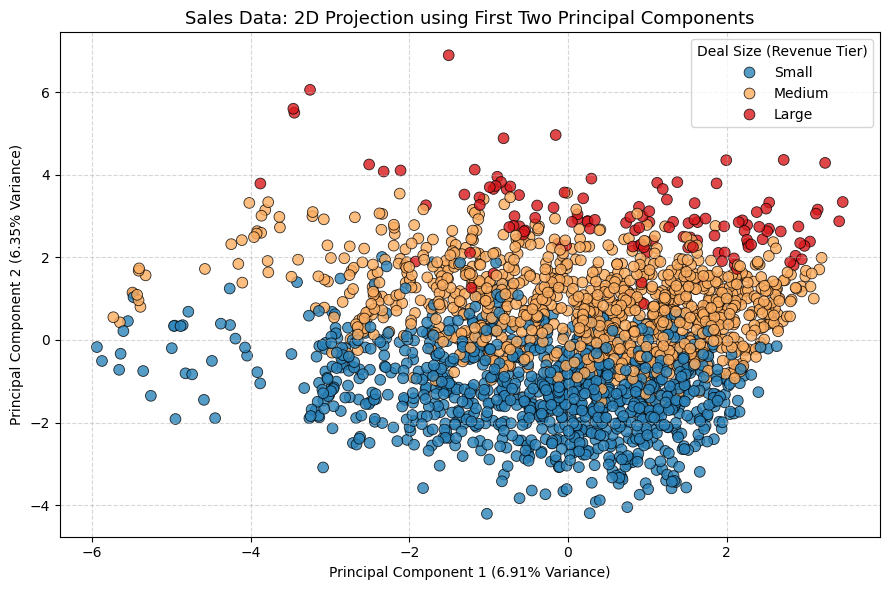

Feature Representation       | Features   | Test Accuracy
------------------------------------------------------------
Original Scaled Data         | 39         | 99.82%
PCA (Top 2 Components)       | 2          | 81.24%
PCA (>= 90% Variance)        | 28         | 88.14%


In [10]:
# 2. Train-Test Split & Standardization
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#3. PCA: Explained Variance Analysis
# ==========================================
# Fit full PCA to compute cumulative variance
pca_full = PCA().fit(X_train_scaled)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

print("Cumulative Explained Variance (Top 10 Components):")
for i, var in enumerate(cum_variance[:10], 1):
    print(f"  PC{i}: {var * 100:.2f}%")

# Select top components retaining >= 90% cumulative variance
pca_90 = PCA(n_components=0.90, random_state=42)
X_train_pca90 = pca_90.fit_transform(X_train_scaled)
X_test_pca90 = pca_90.transform(X_test_scaled)

print(f"\nRetained {pca_90.n_components_} components to capture >= 90% variance.\n")

# ==========================================
# 4. 2D Visualization (Top 2 Principal Components)
# ==========================================
pca_2d = PCA(n_components=2, random_state=42)
X_train_pca2 = pca_2d.fit_transform(X_train_scaled)

var_pc1 = pca_2d.explained_variance_ratio_[0] * 100
var_pc2 = pca_2d.explained_variance_ratio_[1] * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_train_pca2[:, 0],
    y=X_train_pca2[:, 1],
    hue=y_train,
    hue_order=['Small', 'Medium', 'Large'],
    palette={'Small': '#2b83ba', 'Medium': '#fdae61', 'Large': '#d7191c'},
    s=60,
    edgecolor='k',
    alpha=0.8
)
plt.title("Sales Data: 2D Projection using First Two Principal Components", fontsize=13)
plt.xlabel(f"Principal Component 1 ({var_pc1:.2f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_pc2:.2f}% Variance)")
plt.legend(title="Deal Size (Revenue Tier)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# 5. Classifier Training & Accuracy Comparison
# ==========================================
# Baseline: Full Original Scaled Features (39 features)
clf_orig = RandomForestClassifier(random_state=42)
clf_orig.fit(X_train_scaled, y_train)
y_pred_orig = clf_orig.predict(X_test_scaled)
acc_orig = accuracy_score(y_test, y_pred_orig)

# Reduced: Top 2 Components (2 features)
clf_pca2 = RandomForestClassifier(random_state=42)
clf_pca2.fit(X_train_pca2, y_train)
X_test_pca2 = pca_2d.transform(X_test_scaled)
y_pred_pca2 = clf_pca2.predict(X_test_pca2)
acc_pca2 = accuracy_score(y_test, y_pred_pca2)

# Reduced: >= 90% Explained Variance (28 features)
clf_pca90 = RandomForestClassifier(random_state=42)
clf_pca90.fit(X_train_pca90, y_train)
y_pred_pca90 = clf_pca90.predict(X_test_pca90)
acc_pca90 = accuracy_score(y_test, y_pred_pca90)

# ==========================================
# 6. Results Summary
# ==========================================
print("=" * 60)
print(f"{'Feature Representation':<28} | {'Features':<10} | {'Test Accuracy':<12}")
print("-" * 60)
print(f"{'Original Scaled Data':<28} | {X_train.shape[1]:<10} | {acc_orig * 100:.2f}%")
print(f"{'PCA (Top 2 Components)':<28} | {2:<10} | {acc_pca2 * 100:.2f}%")
print(f"{'PCA (>= 90% Variance)':<28} | {pca_90.n_components_:<10} | {acc_pca90 * 100:.2f}%")
print("=" * 60)